# PS 3 — Statystyka opisowa, część 1 
**Statystyka Matematyczna — Data Science**

**Wersja dla grupy PS2** 

**Imię i nazwisko:** Marcin Zubowski  
**Data:** 19.10.2026

## Cel zajęć

Na PS będziemy:
- generować dane i przedstawiać je w postaci szeregu rozdzielczego,
- obliczać i interpretować podstawowe miary statystyczne (położenia i zmienności),
- porównywać wyniki uzyskane dla danych indywidualnych oraz szeregu przedziałowego,
- wizualizować dane za pomocą histogramów, łamanych częstości skumulowanej, empirycznej dystrybuanty oraz wykresów pudełkowych,
- interpretować rozkład danych na podstawie obliczonych miar i sporządzonych wykresów.

W miejscach **Najpierw pomyśl** wpisz odpowiedź przed uruchomieniem kodu.  
W miejscach **Wniosek** podaj krótką interpretację, a nie tylko liczbę.

**Ważne:** W kodzie poniżej nie zmieniaj ziarna generatora.

## 0. Przygotowanie i dane 

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
rng = np.random.default_rng(20262)
n = 240
x = np.round(135 + rng.gamma(shape=5, scale=24, size=n), 2)
dane = pd.DataFrame({"czas ukończenia [min]": x})
display(dane.head(10))
print("Liczebność:", len(x))

,czas ukończenia [min]
0,247.85
1,271.39
2,230.97
3,366.43
4,227.56
5,238.30
6,284.84
7,230.17
8,184.88
9,201.32


Liczebność: 240


### Najpierw pomyśl
**Uzupełnij na podstawie powyższych danych:**

jednostka statystyczna: min \
cecha: czas ukończenia  \
typ cechy: ciągła  \
liczebność próby: 240 \
Czy rozkład wydaje się symetryczny? Tak

## 1. Miary położenia z danych indywidualnych
Oblicz średnią, medianę, kwartyle Q1 i Q3 oraz IQR. Do obliczeń pkwartyli rzyjmij konwencję `np.quantile(..., method="linear")`.

In [7]:
srednia = np.mean(x)
mediana = np.median(x)

Q1 = np.quantile(x, q=0.25 ,method="linear")  # użyj np.quantile(..., method="linear")
Q3 = np.quantile(x, q=0.75, method="linear")  # użyj np.qua)ntile(..., method="linear")

IQR = Q3 - Q1

print(f"średnia = {srednia:.2f}")
print(f"mediana = {mediana:.2f}")
print(f"Q1 = {Q1:.2f}")
print(f"Q3 = {Q3:.2f}")
print(f"IQR = {IQR:.2f}")

średnia = 252.75
mediana = 241.39
Q1 = 213.36
Q3 = 282.43
IQR = 69.06


**Interpretacja** średniej, mediany i kwartyli 

**Odpowiedź:** Mediana to środkowa wartość bardziej odporna na skrajności od średniej. Średnia jest większa od mediany, co może wskaywać na to że rozkład będzie lekko skośny. IQR (50% środokwych danych) wskazuje nam jak duże jest rozrzucenie wartości danej cechy.

**Zastosowaną konwencję `np.quantile(..., method="linear")` porównaj z definicją kwantyla ECDF (Empirical Cumulative Distribution Function).**

**Odpowiedź:** ECDF mówi nam jaki procent obserwacji jest nie większych od wartości "x", a zastosowana konwencja `np.quantile(..., method="linear")` wskaże nam odpowiedni kwantyl z wybranych danych.

**Sprawdź liczebności wartości dokładnych**

In [8]:
vc = pd.Series(x).value_counts()  # użyj   pd.Series(x).value_counts()
print("Liczba różnych wartości:", len(vc))
print("Największa liczebność:", vc.max())
print(vc.head())

Liczba różnych wartości: 240
Największa liczebność: 1
247.85    1
271.39    1
230.97    1
366.43    1
227.56    1
Name: count, dtype: int64


**Dlaczego dominanta surowych danych może być niejednoznaczna?** 

**Odpowiedź:** Liczby mogą różnić się o od siebie bardzo niskimi wartościami, a i tak zostaną uznane za różne, co wystąpi również w przypadku gdy różnica między nimi będzie bardzo duża. Nawet w przypadku, gdy znajdziemy 2 takie same wartości nie oznacza to że w całym zbiorze jest najwięcej liczb nie dalekim zakresie. Dopiero, gdy stworzymy grupy będziemy w stanie zobaczyć gdzie znajduje się dominanta. 

## 2. Szereg rozdzielczy przedziałowy
Zbuduj szereg o 8 klasach jednakowej szerokości. W tabeli podaj granice klas, środki, liczebności, częstości względne, liczebności i częstości skumulowane. Sprawdź sumy. Zapisz, jaka jest klasa modalna.

In [19]:
k = 8
granice = np.linspace(np.floor(x.min()), np.ceil(x.max()), k+1)
n_i, _ = np.histogram(x, bins=granice)
srodki = (granice[:-1]+granice[1:])/2
tabela = pd.DataFrame({"od":granice[:-1], "do":granice[1:], "środek":srodki, "n_i":n_i})

tabela["w_i"] =  n_i/n      # częstości względne  w_i = n_i/n
tabela["N_i"] =  tabela["n_i"].cumsum()  # liczebności skumulowane  użyj tabela[....].cumsum()
tabela["W_i"] =  tabela["w_i"].cumsum()  # częstości skumulowane   użyj tabela[...].cumsum()
display(tabela)
print("Sprawdzenie sum:")
print("Σ n_i =", tabela["n_i"].sum())
print("Σ w_i =", tabela["w_i"].sum())

,od,do,środek,n_i,w_i,N_i,W_i
0,154.000,184.875,169.4375,14,0.058333,14,0.058333
1,184.875,215.750,200.3125,53,0.220833,67,0.279167
2,215.750,246.625,231.1875,60,0.250000,127,0.529167
3,246.625,277.500,262.0625,50,0.208333,177,0.737500
4,277.500,308.375,292.9375,22,0.091667,199,0.829167
5,308.375,339.250,323.8125,21,0.087500,220,0.916667
6,339.250,370.125,354.6875,11,0.045833,231,0.962500
7,370.125,401.000,385.5625,9,0.037500,240,1.000000


Sprawdzenie sum:
Σ n_i = 240
Σ w_i = 1.0


### Wniosek

1. Czy otrzymane sumy świadczą o poprawności tabeli? Dlaczego?  
2. Podaj klasę modalną.

1. Tak, otrzymane sumy świadczą o poprawności tabeli, ponieważ otrzymujemy 240 liczbności o 1 w częstościach skumulowanych (tak jak powinno być).

2. Klasa modalna to klasa 2, przedział (215.750, 246.625] o liczebności 60.

## 3. Miary z szeregu przedziałowego
**Oblicz:** średnią ważoną środkami klas, Q1, medianę i Q3 przez interpolację liniową wewnątrz klasy: $q_p=L+\dfrac{pn-N_{poprz}}{n_i}h$.

In [16]:
srednia_gr = np.sum(srodki * n_i)/n  

def kwantyl_gr(p, granice, n_i):
    n = np.sum(n_i)
    pozycja = p * n
    N_i = np.cumsum(n_i)
    klasa = np.where(N_i >= pozycja)[0][0]
    L = granice[klasa]                
    h = granice[klasa+1] - granice[klasa]  
    n_kl = n_i[klasa]
    N_poprz = 0 if klasa == 0 else N_i[klasa-1]
    return L + ((pozycja - N_poprz) / n_kl) * h

q1_gr = kwantyl_gr(0.25, granice, n_i)
me_gr = kwantyl_gr(0.5, granice, n_i)
q3_gr = kwantyl_gr(0.75, granice, n_i)

print("Średnia:", round(srednia_gr, 2))
print("Q1:", round(q1_gr, 2))
print("Mediana:", round(me_gr, 2))
print("Q3:", round(q3_gr, 2))

Średnia: 252.41
Q1: 211.67
Mediana: 243.02
Q3: 281.71


**Wyznacz dominantę interpolowaną z klasy modalnej i dwóch sąsiednich: $D = L + \dfrac{n_m-n_{m-1}}{(n_m-n_{m-1})+(n_m-n_{m+1})}h$**

In [17]:
L = granice[2]
h = granice[2] - granice[2]

nm = n_i[2]
n_prev = n_i[1]
n_next = n_i[3]

D = L + (nm - n_prev) / ((nm - n_prev) + (nm - n_next)) * h
print(round(D, 2))

215.75


## 4. Porównanie wyników 
Zbuduj tabelę porównującą średnią, Q1, medianę i Q3 dla danych indywidualnych i pogrupowanych; dodaj różnicę (grupowane minus indywidualne). Wyjaśnij, skąd biorą się rozbieżności. Uwaga: nie porównuj mechanicznie dominanty ciągłej z najczęściej powtarzaną zaokrągloną obserwacją.

In [18]:
porownanie = pd.DataFrame({
    "miara": ["średnia", "Q1", "mediana", "Q3"],
    "indywidualne": [srednia, Q1, mediana, Q3],  # uzupełnij odpowiednimi wartościami
    "przedziałowe": [srednia_gr, q1_gr, me_gr, q3_gr]   # uzupełnij odpowiednimi wartościami
})
porownanie["różnica"] = (
    porownanie["przedziałowe"] - porownanie["indywidualne"]
)
display(porownanie.round(2))

,miara,indywidualne,przedziałowe,różnica
0,średnia,252.75,252.41,-0.34
1,Q1,213.36,211.67,-1.69
2,mediana,241.39,243.02,1.63
3,Q3,282.42,281.71,-0.71


### Wniosek

Wyjaśnij skąd biorą się rozbieżności między danymi indywidualnymi a pogrupowanymi w przedziały.

W przypadku danych pogrupowanych w przedziały korzystamy z interpolacji do obliczenia mediany czy kwartyli. Średnia jest wtedy przybliżeniem, bo nie znamy pojedynczych obserwacji w danej klasie. Musimy przyjąć równomierne rozklożenie danych w klasie. Oznacza to że wewnątrz klasy większośc wartości znajduje się np. bliżej górnej granicy, ale i tak wykorzystamy środek klasy do obliczeń. Stąd różnica w porówaniu do danych indywidualnych.

## 5. Histogramy i częstości skumulowane
**Narysuj dwa histogramy:** dla 8 i 16 klas.

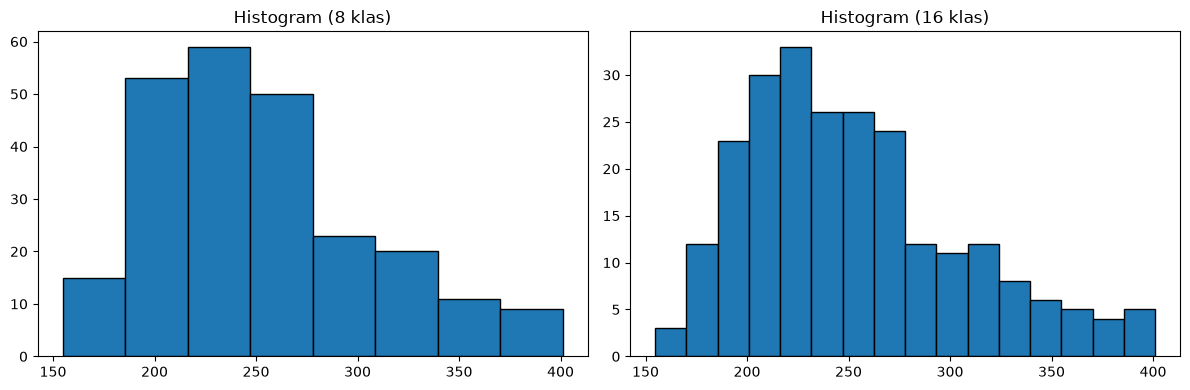

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].hist(x, bins=8, edgecolor="black")
ax[0].set_title("Histogram (8 klas)")
ax[1].hist(x, bins=16, edgecolor="black")  # uzupełnij
ax[1].set_title("Histogram (16 klas)")  # uzupełnij
plt.tight_layout()
plt.show()

Narysuj **łamaną częstości skumulowanej** wyznaczoną na podstawie szeregu przedziałowego z 8 klasami: punkty na granicach klas, rozpoczynając od (lewa granica, 0). Dodaj poziome linie 0.25, 0.5, 0.75.

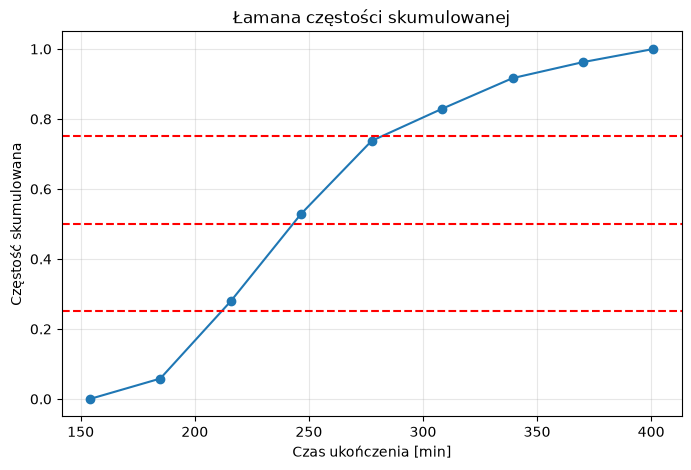

In [21]:
N_i = np.cumsum(n_i)
W_i = N_i / n

x_ogiva = granice
y_ogiva = np.concatenate(([0], W_i)) # łamana

plt.figure(figsize=(8,5))
plt.plot(x_ogiva, y_ogiva, marker="o")

plt.axhline(0.25, ls="--", color="red")
plt.axhline(0.5, ls="--", color="red")  # dodaj kolejną linię
plt.axhline(0.75, ls="--", color="red")  # dodaj kolejną linię

plt.xlabel("Czas ukończenia [min]")
plt.ylabel("Częstość skumulowana")
plt.title("Łamana częstości skumulowanej")
plt.grid(alpha=0.3)
plt.show()

### Wniosek
1. Jak liczba klas zmienia wygląd histogramu?
2. Co można wywnioskować o położeniu kwartylów na podstawie łamanej częstości skumulowanej?

1. Większa liczba klas sprawia, że histogram jest "dokładniejszy". W przypadku niewielu klas wykres będzie składał się z kilku bloków o dużej szerokości przez co można utracić ważne informacje. Trzeba jednak pamiętać też, że więcej klas nie znaczy lepiej, bo histogram może stać się nie czytelny.

2. Na podstawie łamanej można odczytać wartości kwartyli oraz jak bardzo odstają od środka.

## 6. ECDF, boxplot i dodatkowy wykres 
Narysuj schodkową ECDF z danych indywidualnych (bez grupowania) i zestaw ją z łamaną skumulowanych częstości szeregu. 

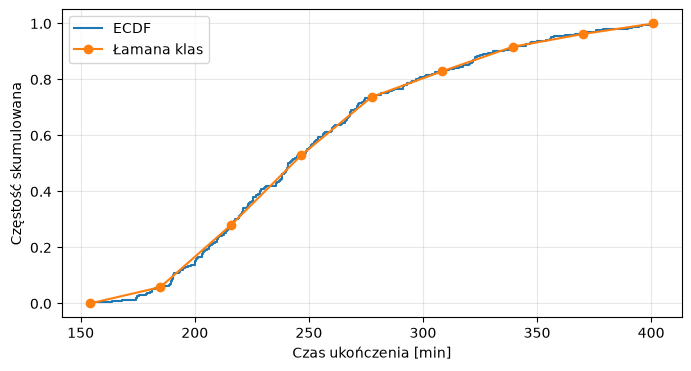

In [22]:
xs = np.sort(x)
ys = np.arange(1, len(xs)+1)/len(xs)

plt.figure(figsize=(8,4))

plt.step(
    np.r_[xs[0], xs],
    np.r_[0, ys],
    where="post",
    label="ECDF"
)

plt.plot(
    granice,
    np.r_[0, tabela["W_i"].to_numpy()],
    "o-",
    label="Łamana klas"
)

plt.xlabel("Czas ukończenia [min]")
plt.ylabel("Częstość skumulowana")
plt.legend()
plt.grid(alpha=0.3)

**Narysuj boxplot oraz jeden dodatkowy wykres: strip plot lub histogram z liniami średniej i mediany.**

/tmp/ipykernel_75242/4139299536.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(x, vert=False)


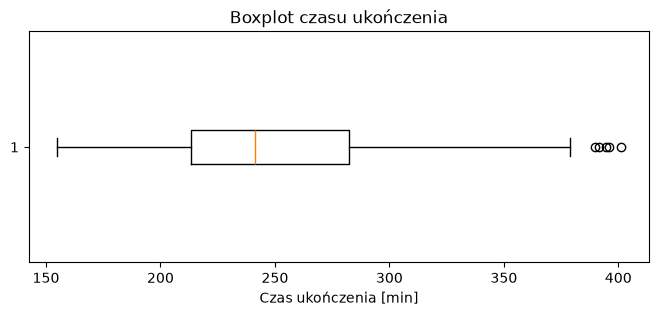

In [23]:
plt.figure(figsize=(8,3))

plt.boxplot(x, vert=False)

plt.xlabel("Czas ukończenia [min]")
plt.title("Boxplot czasu ukończenia")

plt.show()

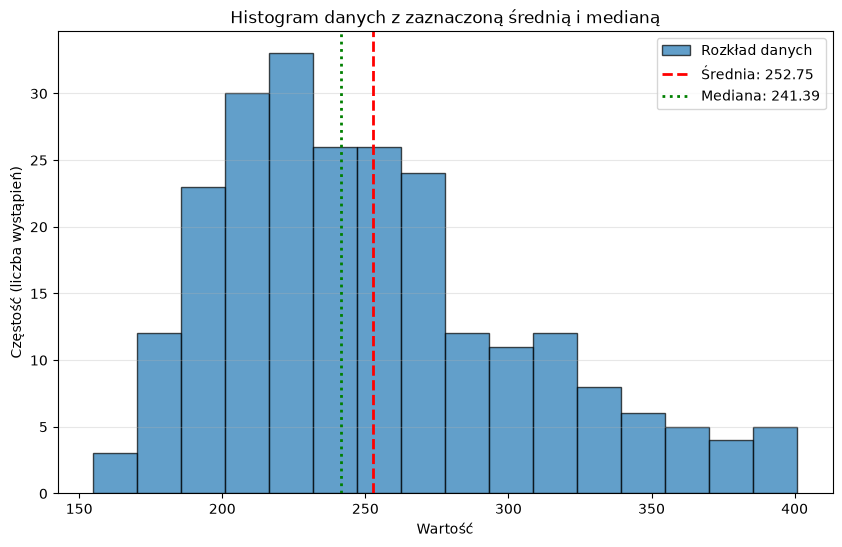

In [28]:
# dodatkowy wykres
plt.figure(figsize=(10, 6))
plt.hist(x, bins=16, edgecolor='black', alpha=0.7, label='Rozkład danych')

plt.axvline(srednia, color='red', linestyle='dashed', linewidth=2, 
            label=f'Średnia: {srednia:.2f}')
plt.axvline(mediana, color='green', linestyle='dotted', linewidth=2, 
            label=f'Mediana: {mediana:.2f}')

plt.title('Histogram danych z zaznaczoną średnią i medianą')
plt.xlabel('Wartość')
plt.ylabel('Częstość (liczba wystąpień)')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

### Wniosek
1. Wyjaśnij różnicę między ECDF i łamaną.
2. Zinterpretuj położenie mediany w pudełku i ewentualne obserwacje odstające.

1. ECDF to wykres schodkowy oparty na danych indywidualnych. Łamana częstości skumulowanej za to wykorzystuje wartości pogrupowane z odpowiednimi liczbami obserwacji. Ostatecznie mają one podobny kształt i nie odstają od siebie w zauważalny sposób.

2. Na boxplocie widzimy, że mediana nie znajduje się idealnie po środku pudełka, a lekko na lewo. Widać również pewne obserwacje odstające (puste kropki) w okolicach wartości 400. Są to pojedyncze wartości z poza Q1 i Q3 (ogony rozkładu).

## 7. Pytania kontrolne
**1. Czym różnią się średnia i mediana?**

Średnia jest wrażliwa na obserwacje skrajne i wykorzystuje wszystkie wartości. Mediana to wartość środkowa i jest bardziej odporna na odstające wartości.

**2. Jak interpretować kwartyle Q1 i Q3?**

Kwartyle dzielą zbiór na 4 równe części (Q1 = 0,25, Q3 = 0,75). 

**3. Dlaczego grupowanie danych powoduje utratę części informacji?**

Zamiast indywidualnych obserwacji mamy grupy złożone z wielu obserwacji. Tracimy wtedy informacje o pojedynczych wartościach, mogą one znajdować się bliżej górnej lub dolnej granicy, lecz nie będziemy tego wiedzieć.

**4. Jaka jest różnica między ECDF a łamaną częstości skumulowanych?**

ECDF to wykres schodkowy oparty na danych indywidualnych. Łamana częstości skumulowanej za to wykorzystuje wartości pogrupowane z odpowiednimi liczbami obserwacji.

**5. Jak rozpoznać obserwacje odstające na boxplocie?**

Puste kropki poza "wąsami".

## 8. Wnioski końcowe 
Napisz 5–7 zdań. Odpowiedz: 
* jaka miara najlepiej opisuje typową wartość,
* co mówi asymetria,
* ile informacji tracimy po grupowaniu
* który wykres najwięcej wyjaśnia?

Podaj co najmniej trzy konkretne wartości liczbowe z analizy.

Typową wartość najlepiej opisuje mediana. Asymetria mówi nam w którą stronę "przesuwa" się wykres w stostunku do symetrycznego. Po grupowaniu tracimy informacje o indywidualnych obserwacjach w danym przedziale, dlatego musimy korzystać z interpolacji. Każdy wykres ma swoje zastosowanie. Boxplot pozwala nam zobaczyć odstające obserwacje, histogram rozłożenie grup oraz ich liczebność, a ECDF czy łamana jaka część danych nie przekracza danej wartości oraz tempo narastania liczebności. Nawet jeśli wykresy pokazują to samo, to robią to często w inny sposób, więc ciężko stwierdzić, który wykres jest najlepszy.

# 9. Deklaracja wykorzystania AI

Korzystanie z AI jest dozwolone do:
- wyjaśniania pojęć,
- wyszukiwania składni Pythona,
- diagnozowania błędów,
- dyskusji nad interpretacją wyników.

**Czy korzystałem/am z AI?** TAK

**Narzędzie/narzędzia:**  
Gemini

**Do czego wykorzystałem/am AI?**  
Stworzenie ostatniego wykresu

**Podaj jeden przykład pytania/promptu:**  
Stwórz kod generujący histogram z liniami średniej i mediany dla zbioru liczb x zapisanego w tablicy numpy w pythonie korzystając z biblioteki matplotlib.

**Czy odpowiedź AI wymagała sprawdzenia lub poprawienia?**  
Wszystko się zgadzało

> Oświadczam, że rozumiem przedstawiony kod, potrafię wyjaśnić zastosowane funkcje i samodzielnie interpretuję wyniki.

# Oddanie raportu

1. Uzupełnij wszystkie miejsca oznaczone **UZUPEŁNIJ**, **Najpierw pomyśl** i **Wniosek**.
2. Uruchom notebook od początku do końca (`Run All`).
3. Pozostaw widoczne wyniki i wykresy.
4. Zapisz notebook jako `Nazwisko_Imie_PS03_gr2.ipynb`.
5. Wyeksportuj do HTML jako `Nazwisko_Imie_PS03_gr2.html`.
6. Oddaj pliki zgodnie z instrukcją prowadzącego.
